# StreamLoop — ajustando el modelo de cancelación

La búsqueda tiene que demostrar que la configuración final no es el primer `.fit()`. El orden es fijo:

1. Cargar el CSV oficial y separar `Churn` con un mapa fijo (`Yes`/`No`).
2. Dividir entrenamiento y test **antes** de ajustar nada.
3. Línea base: `Pipeline` con preprocesamiento interno e hiperparámetros por defecto. Una puntación en el test.
4. `RandomizedSearchCV` amplio, solo sobre el entrenamiento, `n_jobs=-1`, `refit=True`, F2 (beta=2).
5. Rejilla local construida con esos `cv_results_`, luego `GridSearchCV` con la misma métrica y los mismos pliegues.
6. Mirar la media y la desviación entre pliegues. Elegir dentro de una banda de 0.01 de F2.
7. Puntuar el modelo elegido en el test **una vez**, con las mismas métricas que la línea base.

F2 pone más peso en el recall de la cancelación: StreamLoop pierde más si un cliente se va sin que nadie lo marque que si manda una oferta de retención de más. Accuracy no es el `scoring`.

La orquestación vive en `src/streamloop/study.py` (`run_study`). Este notebook la ejecuta y muestra cada resultado. No vuelve a puntuar el test por su cuenta.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd

from streamloop.data import load_telco
from streamloop.pipeline import build_pipeline
from streamloop.report import render_summary, write_deliverables
from streamloop.search import BROAD_SPACE, space_size
from streamloop.study import PRODUCTION_CONFIG, run_study
from streamloop.util import SCORING_REASON_ES

print("repo", ROOT)
print("config", PRODUCTION_CONFIG)
print("broad combinations", space_size(BROAD_SPACE))
print(SCORING_REASON_ES)

repo /workspace
config StudyConfig(random_state=42, test_size=0.2, cv=5, n_iter=24, n_jobs=-1, near_tie=0.01, model_kwargs=None)
broad combinations 1280
StreamLoop pierde más dinero cuando un cliente cancela sin que nadie lo detecte que cuando una oferta de retención llega a alguien que se habría quedado. La búsqueda maximiza F2 (F-beta con beta=2) sobre la clase positiva Churn=Yes. F2 pesa más el recall que la precision. No se usa el accuracy por defecto de scikit-learn: trata los dos errores igual y queda inflado por el grupo más grande, el de quienes no cancelan.


## Dataset

URL del enunciado. El archivo no se guarda en git. El loader rechaza un SHA-256 distinto del CSV público fijado en `PROVENANCE.md`.

In [2]:
frame, meta = load_telco()
print("rows", meta["rows"], "bytes", meta["bytes"])
print("sha256", meta["sha256"])
print("blank TotalCharges", meta["blank_total_charges"])
print(frame["Churn"].value_counts().to_string())
print(frame.drop(columns=["customerID"]).dtypes.to_string())

rows 7043 bytes 970457
sha256 16320c9c1ec72448db59aa0a26a0b95401046bef5d02fd3aeb906448e3055e91
blank TotalCharges 11
Churn
No     5174
Yes    1869
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str


## Pipeline

El preprocesamiento no se aplica antes de la división. `PrepareColumns` quita `customerID` y convierte `TotalCharges`. El imputer y el one-hot viven en el mismo `Pipeline` que el clasificador, así que solo ven las filas de cada `fit`.

In [3]:
pipeline = build_pipeline()
print(pipeline)
print("model overrides vs a bare constructor are applied inside the study; the unfitted model is:")
print(pipeline.named_steps["model"])

Pipeline(steps=[('prepare', PrepareColumns()),
                ('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=F

## Estudio

`run_study` divide, ajusta la línea base, corre la búsqueda aleatoria, acota la rejilla, corre `GridSearchCV` y puntúa el test por segunda vez. Si el ledger no queda en `baseline`, `final`, la celda falla.

In [4]:
result = run_study(frame, config=PRODUCTION_CONFIG, dataset_meta=meta)
assert result["ledger"] == ["baseline", "final"]
assert result["random_search"]["n_jobs"] == -1
assert result["grid_search"]["n_jobs"] == -1
assert result["random_search"]["refit"] is True
assert result["grid_search"]["refit"] is True
assert result["scoring"]["name"] == "f2"
assert result["split"]["n_train"] + result["split"]["n_test"] == result["split"]["n_full"]
print(render_summary(result))

StreamLoop churn tuning
Dataset rows: 7043  source: https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv
SHA-256: 16320c9c1ec72448db59aa0a26a0b95401046bef5d02fd3aeb906448e3055e91
Split: 5634 train / 1409 test, stratified, random_state=42
Scoring: F2 (beta=2). A missed churn costs more than an unneeded retention offer.
Baseline test F2: 0.5473  recall: 0.5294  precision: 0.6326
Random search: 24 draws of 1280, best CV F2 0.5542 ± 0.0267, n_jobs=-1
Grid: 48 candidates, best CV F2 0.5574 ± 0.0318
Selected: l2_regularization=0.1, learning_rate=0.25, max_depth=3, max_iter=50, min_samples_leaf=80
Delivery: La regla de estabilidad eligió un candidato distinto del campeón de refit. Se ajustó un pipeline nuevo una sola vez sobre el entrenamiento con esos hiperparámetros. No se llamó fit sobre best_estimator_.
Final test F2: 0.5506  recall: 0.5267  precision: 0.6724  delta F2: +0.0033
Test-set evaluations: baseline, final
Wrote tuning_report.md

## Línea base y modelo final, mismas métricas

Accuracy no entra en la tabla. Los conteos permiten ver cuántas cancelaciones atrapa cada modelo.

In [5]:
rows = []
for key, label in (("f2", "F2"), ("recall_churn", "Recall (churn)"), ("precision_churn", "Precision (churn)")):
    row = result["comparison"][key]
    rows.append({"metric": label, "baseline": row["baseline"], "tuned": row["tuned"], "delta": row["delta"]})
comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))
print("baseline counts", {k: result["baseline"]["metrics"][k] for k in ("true_positive", "false_negative", "false_positive", "support_churn")})
print("tuned counts", {k: result["tuned"]["metrics"][k] for k in ("true_positive", "false_negative", "false_positive", "support_churn")})
print("baseline overrides", result["baseline"]["overrides"])
print("final hyperparameters", result["tuned"]["params_text"])

           metric  baseline    tuned     delta
               F2  0.547264 0.550587  0.003323
   Recall (churn)  0.529412 0.526738 -0.002674
Precision (churn)  0.632588 0.672355  0.039767
baseline counts {'true_positive': 198, 'false_negative': 176, 'false_positive': 115, 'support_churn': 374}
tuned counts {'true_positive': 197, 'false_negative': 177, 'false_positive': 96, 'support_churn': 374}
baseline overrides {'random_state': 42}
final hyperparameters l2_regularization=0.1, learning_rate=0.25, max_depth=3, max_iter=50, min_samples_leaf=80


## `cv_results_`: media y dispersión entre pliegues

La banda es de 0.01 de F2 de validación bajo la mejor media. Dentro de esa banda gana la menor desviación entre pliegues. `refit=True` ya reentrenó al campeón de la media; si la regla lo confirma, ese objeto se usa tal cual.

In [6]:
from streamloop.util import format_params

chosen_index = result["decision"]["chosen"]["index"]
champion_index = result["decision"]["champion"]["index"]
table = []
for row in sorted(result["grid_search"]["candidates"], key=lambda item: (-item["mean_f2"], item["std_f2"])):
    roles = []
    if row["index"] == champion_index:
        roles.append("refit champion")
    if row["index"] == chosen_index:
        roles.append("delivered")
    table.append({
        "index": row["index"],
        "role": ", ".join(roles),
        "mean_f2": round(row["mean_f2"], 4),
        "std_f2": round(row["std_f2"], 4),
        "folds": ", ".join(f"{score:.3f}" for score in row["folds"]),
        "params": format_params(row["params"]),
    })
stability = pd.DataFrame(table)
print(result["decision"]["rule"])
print(result["decision"]["how"])
print("band size", result["decision"]["band_size"], "used refit object", result["decision"]["used_refit_best_estimator"])
print("grid", result["grid_search"]["param_grid"])
print(stability.head(12).to_string(index=False))

Entre los candidatos de la rejilla a como máximo 0.01 de F2 de validación de la mejor media, se elige la menor desviación entre pliegues. Si empatan, gana la media más alta y, si media y desviación coinciden, el campeón que ya reentrenó refit=True.
La regla de estabilidad eligió un candidato distinto del campeón de refit. Se ajustó un pipeline nuevo una sola vez sobre el entrenamiento con esos hiperparámetros. No se llamó fit sobre best_estimator_.
band size 19 used refit object False
grid {'model__learning_rate': [0.1, 0.15, 0.25], 'model__max_depth': [3, 5], 'model__max_iter': [50, 100], 'model__min_samples_leaf': [40, 80], 'model__l2_regularization': [0.1, 1.0]}
 index           role  mean_f2  std_f2                             folds                                                                                    params
    12 refit champion   0.5574  0.0318 0.551, 0.505, 0.597, 0.582, 0.552  l2_regularization=0.1, learning_rate=0.15, max_depth=5, max_iter=50, min_samples_leaf=40


## Informe y gráficas

Esta celda reescribe `tuning_report.md`, el resumen corto `results/metrics.json` y `docs/figures/` desde el resultado que acaba de calcularse. El volcado completo de la búsqueda no se versiona.

{'report': '/workspace/tuning_report.md', 'metrics': '/workspace/results/metrics.json', 'figures': {'baseline_vs_tuned': '/workspace/docs/figures/baseline_vs_tuned.png', 'grid_fold_stability': '/workspace/docs/figures/grid_fold_stability.png', 'random_search_scores': '/workspace/docs/figures/random_search_scores.png'}}


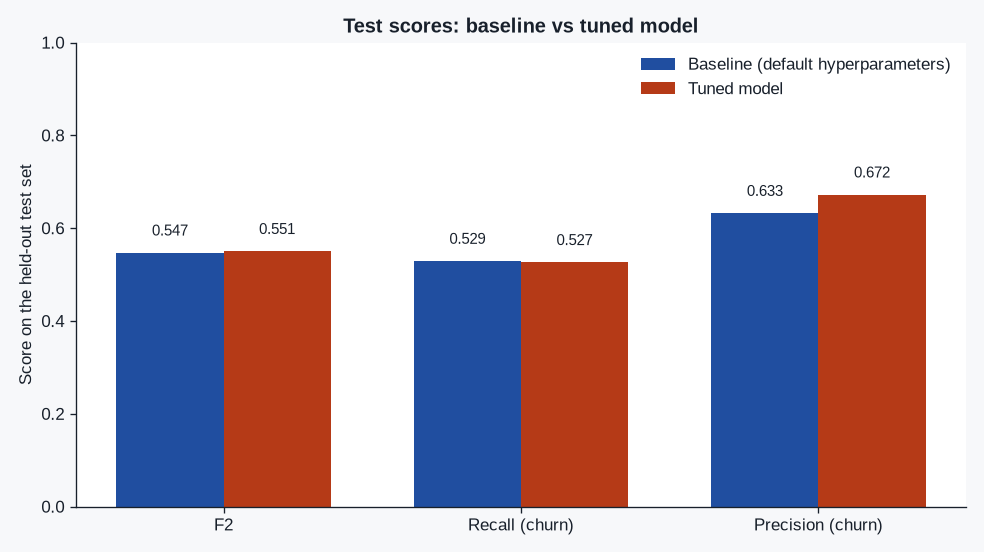

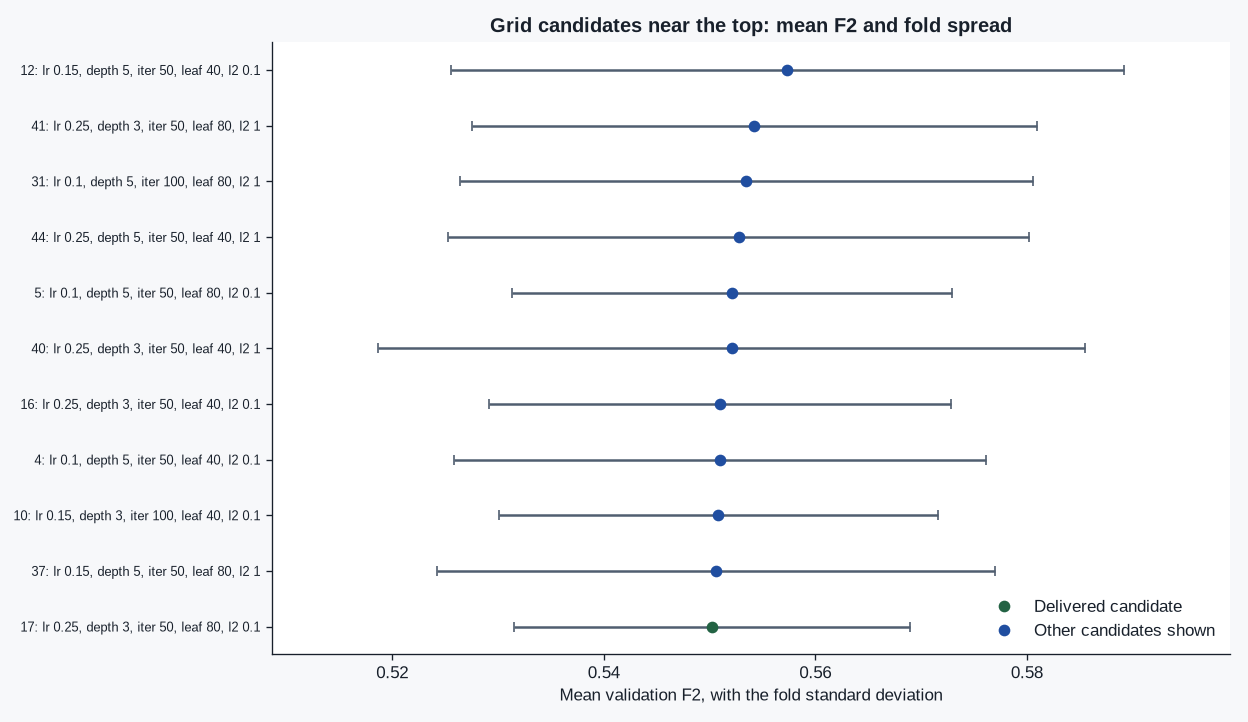

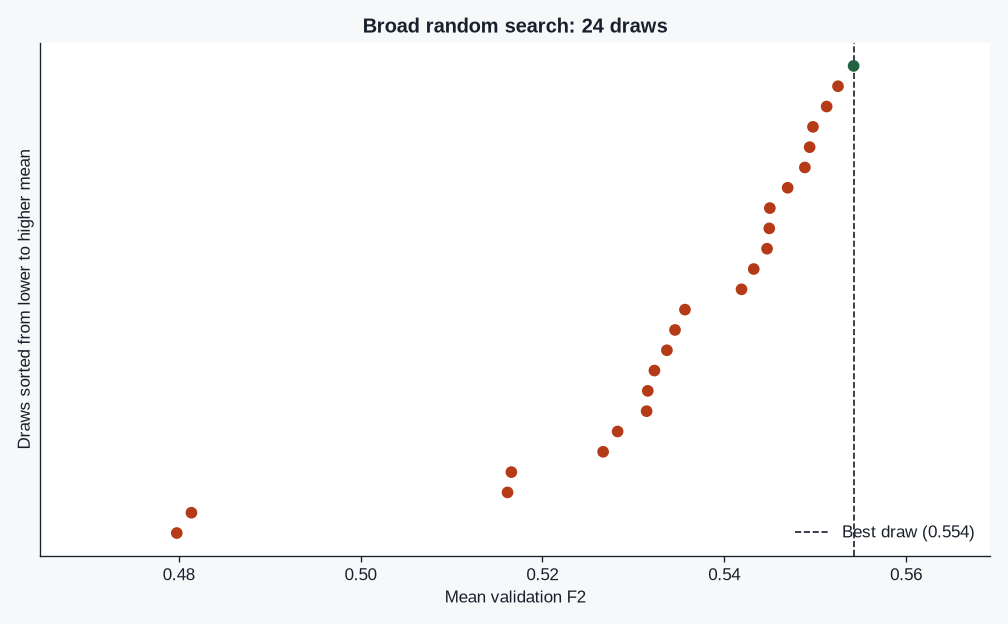

In [7]:
written = write_deliverables(result, ROOT)
print(written)
from IPython.display import Image, display
display(Image(filename=str(ROOT / "docs" / "figures" / "baseline_vs_tuned.png")))
display(Image(filename=str(ROOT / "docs" / "figures" / "grid_fold_stability.png")))
display(Image(filename=str(ROOT / "docs" / "figures" / "random_search_scores.png")))